# 02 - Decision Tree

**What is it?** A Decision Tree asks a sequence of yes/no questions about the features (e.g. *"Total_Trans_Ct <= 54?"*) and splits the customers at each step until the groups are as pure as possible. The final group (leaf) a customer lands in gives the prediction, and the share of churners in that leaf is the churn probability.

**Why use it here?**
- It captures **non-linear patterns and interactions** (e.g. "low transaction count *and* low balance") that Logistic Regression cannot.
- It is easy to explain - the tree can be drawn and read like a set of business rules.
- It needs no scaling and is not affected by outliers or skew (it only compares values against thresholds).

**Main risk:** an unrestricted tree keeps splitting until it has memorised the training data -> **overfitting**. This notebook checks for that and fixes it.

Run `00_prepare_data.ipynb` first. Every model uses the same 80/20 stratified split (seed 42).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve() / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

from common import (CLASS_NAMES, SEED, build_preprocessor, compute_metrics, get_train_test,
                    plot_confusion_matrix, plot_roc_curve, train_and_evaluate)

X_train, X_test, y_train, y_test = get_train_test()


def make_tree(**params):
    return Pipeline([("prep", build_preprocessor(X_train)),
                     ("clf", DecisionTreeClassifier(random_state=SEED, **params))])


def train_vs_test(pipe):
    rows = [compute_metrics(y, pipe.predict(X), pipe.predict_proba(X)[:, 1])
            for X, y in [(X_train, y_train), (X_test, y_test)]]
    return pd.DataFrame(rows, index=["Train", "Test"]).round(4)

## 1. Baseline: default tree (no limits)

In [2]:
default_tree = make_tree().fit(X_train, y_train)
t = default_tree.named_steps["clf"]
print(f"Depth: {t.get_depth()} | Leaves: {t.get_n_leaves()}")
train_vs_test(default_tree)

Depth: 19 | Leaves: 304


,Accuracy,AUC,Precision,Recall,F1,MCC
Train,1.0000,1.000,1.0000,1.0000,1.0000,1.000
Test,0.9373,0.883,0.8056,0.8031,0.8043,0.767


**Observation:** the default tree grows **19 levels deep with 304 leaves** and scores a perfect **1.0 on every training metric** - it has memorised the training customers. On the test set F1 drops to 0.80 and AUC to only 0.88 (its leaves are so small that most probabilities are exactly 0 or 1, so it cannot rank customers well).

**Action needed? Yes - limit the tree's size.** A perfect training score is a classic sign of **overfitting**: the model learned noise that won't repeat on new customers.

## 2. Hyperparameter tuning (GridSearchCV)
We search for the tree size that generalizes best:
- `max_depth` - maximum number of questions from root to leaf.
- `min_samples_leaf` - minimum customers per leaf (bigger leaves = smoother, more reliable probabilities).

**How:** 5-fold stratified cross-validation **on the training set only** - each setting is trained on 4/5 of the training data and scored on the remaining 1/5, five times. The test set is never used for choosing, so it stays an honest final check. Scoring = **F1**, because accuracy is misleading with 16% churners.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
param_grid = {
    "clf__max_depth": [3, 4, 5, 6, 7, 8, 10, 12],
    "clf__min_samples_leaf": [1, 5, 10, 20],
}
grid = GridSearchCV(make_tree(), param_grid, scoring="f1", cv=cv, n_jobs=-1).fit(X_train, y_train)

best_params = {k.replace("clf__", ""): v for k, v in grid.best_params_.items()}
print("Best parameters:", best_params)
print(f"Best cross-validated F1: {grid.best_score_:.4f}")

Best parameters: {'max_depth': 6, 'min_samples_leaf': 1}
Best cross-validated F1: 0.8287


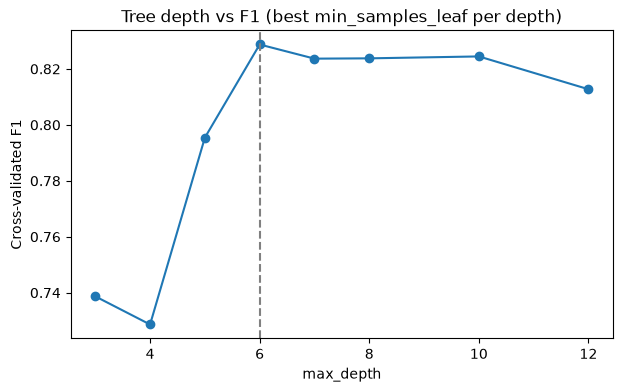

In [4]:
cv_results = pd.DataFrame(grid.cv_results_)
by_depth = cv_results.groupby("param_clf__max_depth")["mean_test_score"].max()

ax = by_depth.plot(marker="o", figsize=(7, 4))
ax.axvline(best_params["max_depth"], ls="--", c="grey")
ax.set_xlabel("max_depth")
ax.set_ylabel("Cross-validated F1")
ax.set_title("Tree depth vs F1 (best min_samples_leaf per depth)")
plt.show()

**Observation:** F1 rises quickly up to **depth 6 (0.829)** and then flattens / slowly drops - deeper trees add complexity without improving generalization. Very shallow trees (3-4) are too simple to capture the pattern (underfitting).

## 3. Default vs tuned - 5-fold cross-validation
Comparing on 5 different validation folds is more reliable than a single test split.

In [5]:
rows = {}
for name, pipe in [("Default (depth 19)", make_tree()), (f"Tuned {best_params}", make_tree(**best_params))]:
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["f1", "matthews_corrcoef", "roc_auc"])
    rows[name] = {m: f"{scores['test_' + m].mean():.4f} +/- {scores['test_' + m].std():.4f}"
                  for m in ["f1", "matthews_corrcoef", "roc_auc"]}
pd.DataFrame(rows).T

,f1,matthews_corrcoef,roc_auc
Default (depth 19),0.8087 +/- 0.0270,0.7730 +/- 0.0321,0.8830 +/- 0.0172
"Tuned {'max_depth': 6, 'min_samples_leaf': 1}",0.8287 +/- 0.0156,0.7987 +/- 0.0189,0.9460 +/- 0.0101


**Observation:** the tuned tree is better on **all three** metrics (F1 0.829 vs 0.809, MCC 0.799 vs 0.773, AUC 0.946 vs 0.883) and its scores vary less between folds (smaller +/-), i.e. it is more **stable**.

**Action needed? Yes - use the tuned tree as the final model.**

## 4. Final model: train & save
`train_and_evaluate()` fits the tuned tree on the full training set, scores the test set, and saves `model/decision_tree.joblib` and `results/metrics.csv`.

In [6]:
model = DecisionTreeClassifier(random_state=SEED, **best_params)
result = train_and_evaluate("decision_tree", model)
pd.DataFrame([result["metrics"]], index=["Decision Tree (tuned)"])

,Accuracy,AUC,Precision,Recall,F1,MCC
Decision Tree (tuned),0.9368,0.9476,0.8456,0.7415,0.7902,0.7554


## 5. Overfitting check (train vs test)

In [7]:
tuned_tree = result["pipeline"]
t = tuned_tree.named_steps["clf"]
print(f"Depth: {t.get_depth()} | Leaves: {t.get_n_leaves()}")
train_vs_test(tuned_tree)

Depth: 6 | Leaves: 47


,Accuracy,AUC,Precision,Recall,F1,MCC
Train,0.9564,0.9679,0.8984,0.8218,0.8584,0.8339
Test,0.9368,0.9476,0.8456,0.7415,0.7902,0.7554


**Observation:** 47 leaves instead of 304, and the train-test gap shrinks from "perfect vs 0.80" to **F1 0.86 vs 0.79** - a normal, healthy gap. AUC on the test set jumps from 0.88 to **0.95**.

**Note on the test score:** on this one test split the tuned tree's F1 (0.790) is slightly below the default tree's (0.804). With only 325 churners in the test set, a 0.014 difference is about 4-5 customers - within random noise. We choose the model by **cross-validation**, not by the test set; picking whichever looks best on the test set would turn the test set into a training signal and make the final score over-optimistic.

## 6. Confusion matrix

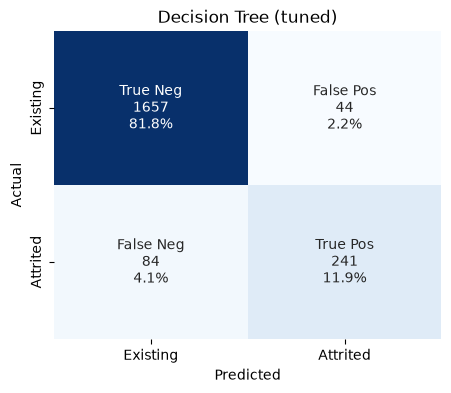

In [8]:
plot_confusion_matrix(result["y_test"], result["y_pred"], title="Decision Tree (tuned)")

**Observation:**
- **True Pos 241** churners caught, **False Neg 84** missed (26% of churners) - much better than Logistic Regression (126 missed).
- **False Pos 44** - same low number of false alarms as Logistic Regression.
- The tree catches more churners **without** raising false alarms, because it can combine conditions (interactions) a linear model can't.

## 7. Classification report

In [9]:
print(classification_report(result["y_test"], result["y_pred"], target_names=CLASS_NAMES, digits=4))

              precision    recall  f1-score   support

    Existing     0.9518    0.9741    0.9628      1701
    Attrited     0.8456    0.7415    0.7902       325

    accuracy                         0.9368      2026
   macro avg     0.8987    0.8578    0.8765      2026
weighted avg     0.9347    0.9368    0.9351      2026



## 8. ROC curve

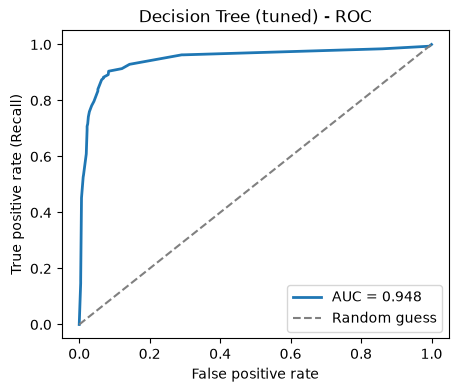

In [10]:
plot_roc_curve(result["y_test"], result["y_prob"], title="Decision Tree (tuned) - ROC")

**Observation:** AUC = 0.948, higher than Logistic Regression (0.932). The curve has visible steps because a tree only produces as many distinct probabilities as it has leaves (47).

## 9. Feature importance
How much each feature reduced impurity across all splits (sums to 1).

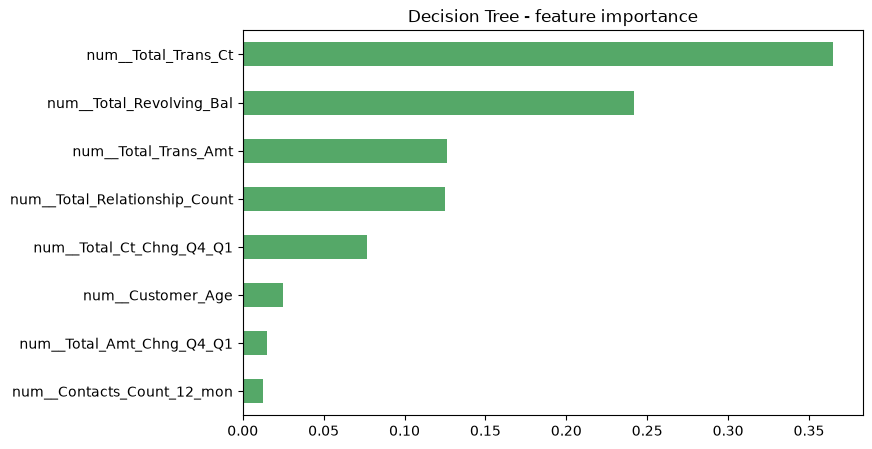

In [11]:
names = tuned_tree.named_steps["prep"].get_feature_names_out()
importance = pd.Series(t.feature_importances_, index=names).sort_values()
ax = importance[importance > 0.005].plot.barh(color="#55A868", figsize=(8, 5))
ax.set_title("Decision Tree - feature importance")
plt.show()

**Observation:**
- **Total_Trans_Ct (0.37)** and **Total_Revolving_Bal (0.24)** do most of the work, followed by Total_Trans_Amt and Total_Relationship_Count (~0.13 each) and Total_Ct_Chng_Q4_Q1 (0.08).
- These 5 features carry **~93%** of the importance; the categorical features (gender, income, education, card) are almost unused - consistent with the EDA, where they showed only small differences in churn rate.

## 10. The tree's top rules (first 3 levels)

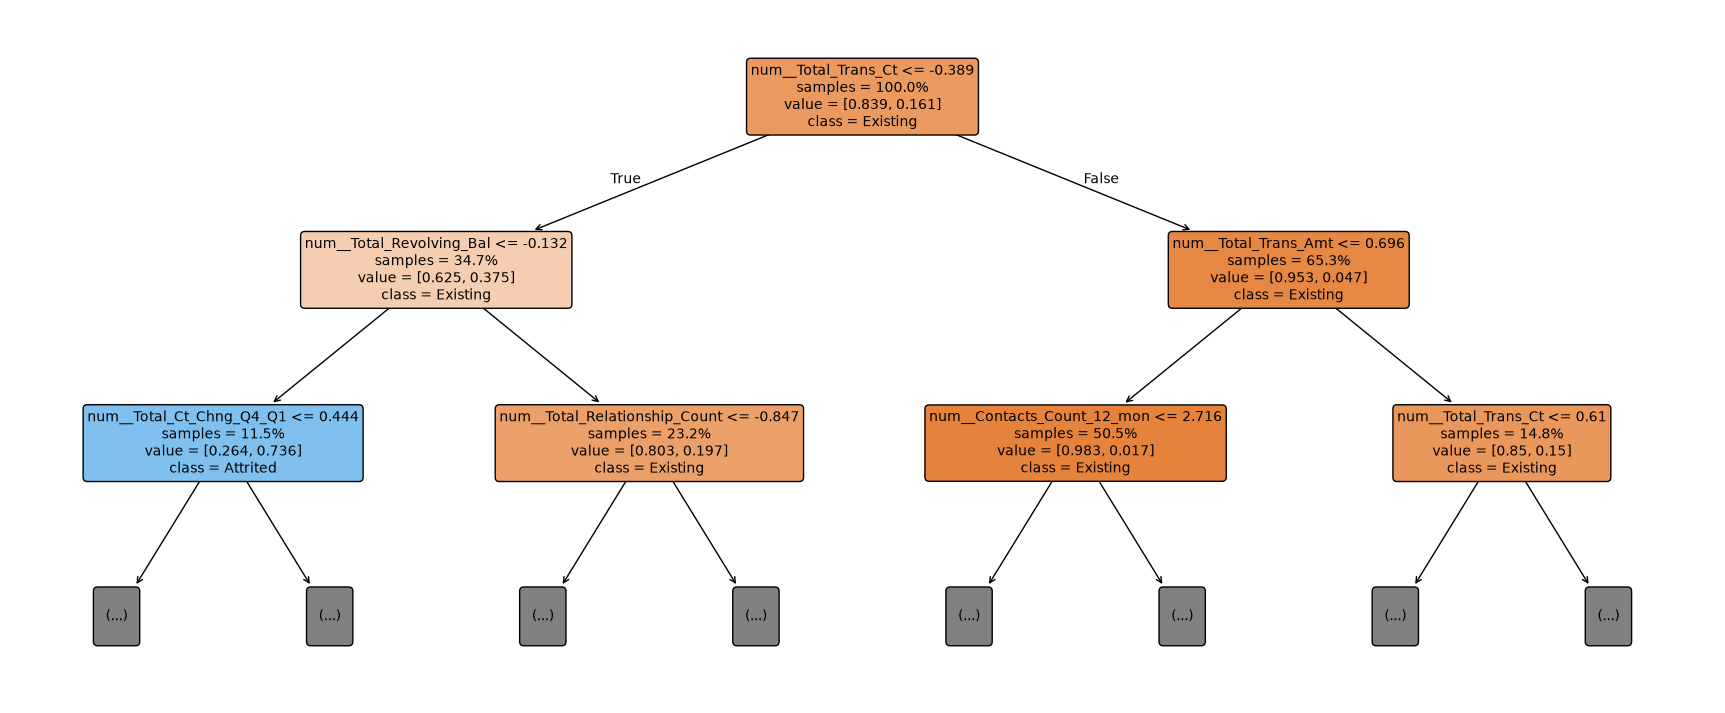

In [12]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(t, max_depth=2, feature_names=names, class_names=CLASS_NAMES, filled=True,
          rounded=True, impurity=False, proportion=True, fontsize=10, ax=ax)
plt.show()

**How to read it:** each box shows the question, the share of customers reaching it, and the class mix. **Blue** boxes lean towards *Attrited*, **orange** towards *Existing* (darker = purer). (Numeric thresholds are on the transformed scale from the preprocessing pipeline, so they show the *direction* of a rule rather than raw values.)

**Observation:**
- The very first question is about **Total_Trans_Ct** - the tree immediately separates low-activity customers.
- **Clearest churn rule:** low transaction count -> low revolving balance -> falling activity (low Total_Ct_Chng_Q4_Q1). This group is 11.5% of customers and **73.6% of them churn** (vs 16.1% overall).
- **Clearest loyal rule:** customers with higher transaction counts (65.3% of all) churn only 4.7%.
- This matches the EDA finding that churners use their card much less and carry no balance.

## Summary - Decision Tree
- Default tree **overfits** (train = 1.0, depth 19, 304 leaves); limited to **max_depth = 6** via 5-fold cross-validation.
- **Test: Accuracy 0.937, AUC 0.948, Precision 0.846, Recall 0.742, F1 0.790, MCC 0.755.**
- Compared with Logistic Regression: catches **42 more churners** (241 vs 199) with the same number of false alarms, and higher AUC - the non-linear rules suit this data.
- Relies mainly on transaction count, revolving balance and transaction amount.